In [45]:
"""
In this code I am running Chinyemba's 2x2 code on hardware for reproducibility and to understand the current implementaton. 

The python version wasn't provided so I am using version 3.10 as it is the lowest version that has worked for me personally with qiskit

Needed for using jupyter notebook on vscode (windows)
- pip install ipykernel

Needed to handle datasets (pandas is my preference)
- pip install pandas

Needed for utilizing huggingface datasets
- pip install fsspec
- pip install huggingface_hub

Needed for qiskit visualizations. He forgot to include this in the needed imports
- pip install pylatexenc

Needed for simulator
- pip install qiskit qiskit-aer

You need this to run in ipynb notebooks on vs code (in case you don't use google colab)

Add this paper to overleaf "https://www.nature.com/articles/s41597-023-02181-4""paper linked to datatset"
- Lowfield MRI -  uses magnets with field strengths below 1 Tesla to create detailed images of the body, often prioritizing accessibility and lower cost over image resolution compared to high-field systems. 
  These systems are smaller, require less shielding, and can operate without liquid helium, making them suitable for resource-limited settings.
"""

'\nIn this code I am running Chinyemba\'s 2x2 code on hardware for reproducibility and to understand the current implementaton. \n\nThe python version wasn\'t provided so I am using version 3.10 as it is the lowest version that has worked for me personally with qiskit\n\nNeeded for using jupyter notebook on vscode (windows)\n- pip install ipykernel\n\nNeeded to handle datasets (pandas is my preference)\n- pip install pandas\n\nNeeded for utilizing huggingface datasets\n- pip install fsspec\n- pip install huggingface_hub\n\nNeeded for qiskit visualizations. He forgot to include this in the needed imports\n- pip install pylatexenc\n\nNeeded for simulator\n- pip install qiskit qiskit-aer\n\nYou need this to run in ipynb notebooks on vs code (in case you don\'t use google colab)\n\nAdd this paper to overleaf "https://www.nature.com/articles/s41597-023-02181-4""paper linked to datatset"\n- Lowfield MRI -  uses magnets with field strengths below 1 Tesla to create detailed images of the body,

# Reconstructing one 2x2 patch on a quantum computer

The notebook runs the smallest image reconstruction: four numbers of measured MRI
k-space, transformed by a quantum Fourier transform on IBM hardware, and compared
against what NumPy gives for the same four numbers.

The four steps below are IBM's Qiskit pattern
([map, optimize, execute, analyse](https://quantum.cloud.ibm.com/docs/en/guides/intro-to-patterns)),
which is how any circuit reaches hardware.

| Step | What happens |
|---|---|
| 0. Setup | Load the data and connect to a device |
| 1. Map | Turn four complex numbers into a two-qubit circuit |
| 2. Optimize | Rewrite that circuit in the gates the device actually has |
| 3. Execute | Run it, and get back a tally of measured outcomes |
| 4. Analyse | Turn the tally into an image and score it |

## 0. Setup

| Package | Import name | What it provides here |
|---|---|---|
| `json` | `json` | Reads the stored job in `results/`, so the notebook runs offline |
| `h5py` | `h5py` | Reads HDF5, the format the MRI dataset ships in |
| `matplotlib` | `plt` | The figures |
| `numpy` | `np` | Arrays, and the `np.fft` the device is scored against |
| `qiskit` | `QuantumCircuit` | The circuit itself |
| `qiskit.circuit.library` | `QFTGate` | The quantum Fourier transform |
| `qiskit.transpiler` | `generate_preset_pass_manager` | Rewrites a circuit for a device |
| `qiskit_ibm_runtime` | `QiskitRuntimeService` | Authenticates and lists devices |
| `qiskit_ibm_runtime` | `SamplerV2` | Runs circuits and returns counts |

In [ ]:
import cmath
from datetime import datetime, timezone
import json
import pandas as pd
import re
import timeit

import h5py
import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import hf_hub_download
from huggingface_hub import snapshot_download
from pathlib import Path
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Gate
from qiskit.circuit.library import QFTGate
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# Add a file called "personal_data.py"
# Make two variables 
# token: Your Api key for ibm quantum
# crn: Your crn for ibm quantum
from personal_data import (token, crn)

np.set_printoptions(precision=4, suppress=True)


I've edited this code to pull from the dataset rather than a file name. The way it was written before, the coder must have downloaded a random image and used it. This way actually incorporates the whole dataset.

In [47]:
# old line to get downloaded file
# M4RAW = "m4raw/multicoil_val/2022061203_T101.h5"

# New line(s)
# This is for t1 scanners\
# THIS WILL DOWNLOAD THE DATASET. If you don't have 30 gb to spare, go ahead and comment it out

# Already downloaded so I commented it out
# path = snapshot_download(
#     repo_id="mylyu/M4Raw_brain",
#     repo_type="dataset",
#     local_dir="./M4Raw_brain",
# )
# print("Dataset saved to:", path)

mri_repo = "M4Raw_brain/metadata"
path = "./M4Raw_brain/metadata/T1_manifest.tsv"
df = pd.read_csv(path, sep="\t")

print(path)
print("Exists:", Path(path).exists())
print("Size:", Path(path).stat().st_size, "bytes")

./M4Raw_brain/metadata/T1_manifest.tsv
Exists: True
Size: 34360 bytes


### The data

One slice of a brain scan from [M4Raw](https://doi.org/10.1038/s41597-023-02181-4),
stored as k-space,

Also very important is checking the actual dataset. I've added lines to show the dataset details

In [48]:
#print( ,"----------------" ,sep="\n")
print("df features: ", df.columns ,"----------------" ,sep="\n")
print("First 5 rows:", df.head(), "----------------" ,sep="\n")
print("df shape: ", df.shape ,"----------------|" ,sep="\n")
# there is no reason why putting "df info: " in the same print statement as df.info should cause
# "df info: " to go to the bottom of the print statement. That's stupid
print("df info: ")
print(df.info() ,"----------------" ,sep="\n")

# The only numeric value is the scan_id and that's just the id so there's no value in this function
#print("df description: ", df.describe() ,"----------------" ,sep="\n") 

print("dataframe null values: ", df.isnull().sum(),"----------------",sep="\n") # shows null per feature (column) in dataset
print("dataframe types",df.dtypes,"----------------", sep="\n")



# Old code (Chinyemba)
# SLICE, COIL = 9, 0

# with h5py.File(M4RAW, "r") as handle:
#     kspace = handle["kspace"][SLICE, COIL]

# print(f"k-space {kspace.shape} complex, slice {SLICE}, coil {COIL}")

df features: 
Index(['scan_id', 'participant_cohort', 'participant_split', 'motion_type',
       'available_repetitions', 'gre_available', 'h5_rep01', 'h5_rep02',
       'h5_rep03', 'h5_rep04', 'h5_rep05', 'h5_rep06'],
      dtype='object')
----------------
First 5 rows:
      scan_id participant_cohort participant_split motion_type  \
0  2022061001           original             train        none   
1  2022061002           original             train        none   
2  2022061003           original             train        none   
3  2022061004           original             train        none   
4  2022061005           original             train        none   

   available_repetitions  gre_available                            h5_rep01  \
0                      3           True  multicoil_train/2022061001_T101.h5   
1                      3           True  multicoil_train/2022061002_T101.h5   
2                      3           True  multicoil_train/2022061003_T101.h5   
3              

M4Raw_brain\multicoil_val\2022061203_T101.h5
kspace dimensions:  (18, 4, 256, 256)
['ismrmrd_header', 'kspace', 'reconstruction_rss']
[('ismrmrd_header', <HDF5 dataset "ismrmrd_header": shape (), type "|O">), ('kspace', <HDF5 dataset "kspace": shape (18, 4, 256, 256), type "<c8">), ('reconstruction_rss', <HDF5 dataset "reconstruction_rss": shape (18, 256, 256), type "<f4">)]
----------------


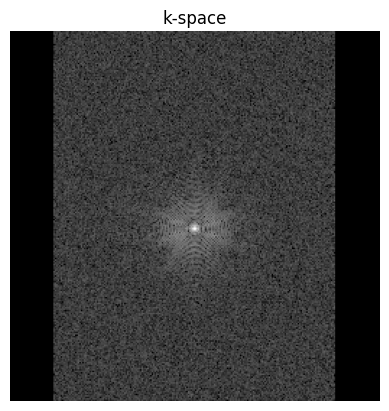

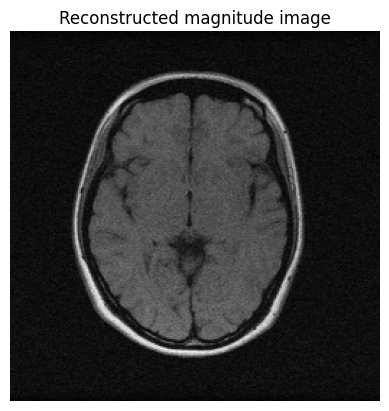

shape: (256, 256)
exact zeros: 0.245513916015625
column magnitudes: [ 0.      0.      0.      0.      0.      0.      0.      0.      0.
  0.      0.      0.      0.      0.      0.      0.      0.      0.
  0.      0.      0.      0.      0.      0.      0.      0.      0.
  0.      0.      0.      4.5756  4.6115  4.6826  4.6139  4.7968  4.5028
  4.514   4.7336  4.6753  4.5897  5.1431  4.8679  4.8385  4.6211  4.7933
  4.5162  4.794   5.0735  4.5188  4.9112  4.6587  4.6121  4.7812  4.4188
  4.6263  4.4161  4.5826  4.7382  4.6887  4.8348  4.4892  4.8705  4.9331
  4.5618  4.6537  4.7015  4.5683  4.5347  4.6706  5.0484  4.6912  4.7393
  4.5901  4.6196  4.7698  4.8574  4.8599  4.8022  4.9763  5.1385  4.9183
  5.0604  4.8072  5.1236  4.7199  5.0464  4.922   4.9832  4.8052  4.9165
  4.8482  5.1801  4.9853  4.9829  4.9757  5.1718  5.2309  5.0837  5.2261
  5.3581  5.1388  5.3184  5.4731  5.5693  5.967   5.6492  5.9576  6.2374
  5.7132  6.5853  6.3792  6.2819  6.9671  6.6835  7.1943  7.3292  7.

In [49]:
# This is where I grab a specific file and continue the given code
# Why he chose the 9th slice and 1st coil no clue
SLICE, COIL = 9, 0

# Why "2022061203"? Because the code given to me used that specific scan_id. Change it and play around with it.
row_M4RAW = df[df["scan_id"] == 2022061203]  
#print(object_M4RAW)
M4RAW_file_path = Path("./M4Raw_brain/", row_M4RAW["h5_rep01"].iloc[0])
print(M4RAW_file_path)

"""
Via the M4Raw paper
All the H5 files are named in the format of “study-id_contrast_repetition-id.h5” (e.g., “2022061003_
FLAIR01.h5”). In each file, the imaging parameters, multi-channel k-space, and the single-repetition images can
be accessed via the dictionary keys of “ismrmrd_header”, “kspace”, and “reconstruction_rss”, respectively. The
k-space dimensions are arranged in the order of slice, coil channel, frequency encoding, and phase encoding,
following the convention of the fastMRI dataset
"""
#np.set_printoptions(threshold=np.inf) for printing large output
with h5py.File(M4RAW_file_path, "r") as handle:
    kspace = handle["kspace"][SLICE, COIL]
    # There are 18 axial slices and 4 coils
    print("kspace dimensions: ", handle["kspace"].shape)
    # Added this to see what's within h5 ffile
    print(list(handle.keys()))
    print(list(handle.items()))
    print("----------------")
    #display(kspace)
    display_kspace = handle["kspace"][()]

    slice_idx = 9
    coil_idx = 0
    k = display_kspace[slice_idx, coil_idx]
    # Visualize k-space magnitude; log scaling reveals low-intensity details.
    # This puts the zeros to the side
    """
    Remember, k is a complex-value so it cannot be shown directly as a regular greyscale image.
    np.abs(k) shows each sample's magnitude, ignoring its phase
    np.log1p(...) applies log(1 + magnitude), compressing the large bright values so weaker k-space details are visible too. It also handles zeros safely

    imshow maps the smallest displayed value to black and the largest to white. With raw magnitude, the strong center values set the display range, so the 
    much weaker outer values all look nearly black.
    The logarithm compresses the range: large values shrink proportionally more than small ones. For example, if the center magnitude is 1000 and an outer 
    value is 1, linear scaling makes the outer value about 0.1% of the maximum; log1p maps them to about 6.9 and 0.69, so the outer value becomes about 10% 
    of the transformed maximum—more visible. NOTEEEEE: log1p is NATURAL LOG not base 10.
    """
    plt.imshow(np.log1p(np.abs(k)), cmap="gray")
    plt.title("k-space")
    plt.axis("off")
    plt.show()
    # Actual image reconstruction
    coil_images = np.fft.fftshift(
    np.fft.ifft2(np.fft.ifftshift(display_kspace[slice_idx], axes=(-2, -1))),
    axes=(-2, -1)
    )
    rss = np.sqrt(np.sum(np.abs(coil_images) ** 2, axis=0))

    plt.imshow(rss, cmap="gray")
    plt.title("Reconstructed magnitude image")
    plt.axis("off")
    plt.show()

    print("shape:", k.shape)
    print("exact zeros:", np.mean(np.abs(k) == 0))
    print("column magnitudes:", np.mean(np.abs(k), axis=0))
    print("row magnitudes:", np.mean(np.abs(k), axis=1))




print(f"k-space {kspace.shape} complex, slice {SLICE}, coil {COIL}")

#### Connecting to a quantum computer

The account was saved once with `QiskitRuntimeService.save_account(...)`, which
writes the token to `~/.qiskit/qiskit-ibm.json` — outside this repository, so no
notebook contains it. Without an account the notebook falls back to a stored run
and every figure below still reproduces.

In [50]:
# def load_saved_account():
#     """Load the IBM Quantum account saved on this machine.

#     Returns:
#         Tuple of (service, online): the service, or None if no account loaded.
#     """
#     try:
#         return QiskitRuntimeService(), True
#     except Exception as problem:
#         print(f"No IBM Quantum account found ({type(problem).__name__}).")
#         print("The notebook will use the stored results.")
#         return None, False

In [ ]:
# Optimize this later. I do not believe you need to call this everytime. 

# I think I can leave this commented out after the first time I run it.
# QiskitRuntimeService.save_account(
#             token=token,
#             instance=crn,
#             set_as_default = True,
#             overwrite=True,
#             channel="ibm_quantum_platform"
#             )

service = QiskitRuntimeService(channel="ibm_cloud", 
                               token=token,
                               instance=crn)

qiskit_runtime_service._discover_account:WARNING:2026-10-14 20:06:20,495: Loading account with the given token. A saved account will not be used.


In [ ]:
# Use this for backend
# You could do least_busy too but this gives the user an option to select whatever backend they find available online
backend_name="ibm_marrakesh"
backend = service.backend(backend_name)

In [ ]:
"""
Old code here
This reads results from a file I do not have. So I will choose a backend myself.
"""
# service, ONLINE = load_saved_account()
# Pinned to the device the stored run used, so the calibration printed here
# describes the same machine the counts came from. results/latest.json records
# which that was, rather than this notebook asserting it.
# with open("results/latest.json", encoding="utf-8") as handle:
#     BACKEND_NAME = json.load(handle)["backend"]
# backend = service.backend(BACKEND_NAME) if ONLINE else None
# if ONLINE:
#     print(f"backend {backend.name}, {backend.num_qubits} qubits, "
#           f"{backend.status().pending_jobs} jobs queued")

'\nThis reads results from a file I do not have. So I will choose a backend myself.\n'

## 1. Map — four numbers into two qubits

The patch is cut from the centre of k-space, which "determines overall contrast,
the ratio of light to dark, in the image", while the edges control resolution [4].
Four numbers from the centre are the four carrying contrast rather than detail.

In [ ]:
"""
Note that this ONLY works when side is even. Also what determines how big the center is?
DO NOTE: That the kspace (256 x 256 pixels) is much bigger than 2x2. 2x2 is the just the cropped region
"""
def crop_centre_patch(array, side):
    """Crop the square patch at the centre of a k-space array.

    Args:
        array: Complex 2D array of k-space.
        side: Length of the patch's side, a power of two.

    Returns:
        Complex array shaped (side, side).
    """
    row, column = array.shape[0] // 2, array.shape[1] // 2
    half = side // 2
    # array [this row through this row, this column through this column]
    return array[row - half:row + half , column - half:column + half]

In [55]:
patch = crop_centre_patch(kspace, 2)
# Checking that each value is a complex number
print(patch[0][0].dtype)

print("the 2x2 patch, as measured:")
for row in patch:
    print("  ", "   ".join(f"{value.real:+8.2f}{value.imag:+7.2f}i" for value in row))

complex64
the 2x2 patch, as measured:
     -27.22 -10.05i     -15.00 -14.00i
      +6.98  +7.57i     +14.00  +8.00i


### Normalising — amplitude encoding

The four numbers enter as the *amplitudes* of a two-qubit state — **amplitude
encoding**, $N$ values in $\log_2 N$ qubits [5]:

$$|\psi_x\rangle \;=\; \frac{1}{\alpha}\sum_{i=1}^{N} x_i\,|i\rangle,
\qquad \alpha = \sqrt{\textstyle\sum_i |x_i|^2}$$


In [ ]:
# This flattens the array
flat = patch.ravel()
# Frobenius norm: the square root of the sum of the absolute squares of its elements. Yes the norm is the length of the data vector
length = np.linalg.norm(flat)
amplitudes = flat / length  

qubits = 2  # two qubits hold the four amplitudes

print(f"length of the vector: {length:.4f}")
print()
print(f"{'basis':>7} {'patch':>8} {'measured':>15} {'normalised':>24} "
      f"{'|a|^2':>13}")
for index, (raw, value) in enumerate(zip(flat, amplitudes)):
    # Qiskit writes the index in binary, high bit first: q1 picks the row,
    # q0 picks the column. That split is why one QFT goes on each qubit.
    bits = format(index, f"0{qubits}b")
    row, column = index // 2, index % 2
    print(f"{'|' + bits + '>':>7} {f'[{row},{column}]':>8} "
            # measured
            f"{raw.real:>+10.2f}{raw.imag:>+9.2f}i "
            # normalized
            f"{value.real:>+12.4f}{value.imag:>+12.4f}i"
            f"{abs(value) ** 2:>9.4f}")
    
print(f"{'sum':>7} {'':>8} {'':>22} {'':>22} "
      # the sum ensuring it maintains normalization condition for wavefunctions  (probabilities must equal 1)
      f"{np.sum(np.abs(amplitudes) ** 2):>9.4f}")

# Qiskit uses little-endian notation for ordering bits. Can't tell what the ordering is saying "high low" "q1 q0".
# the least significant bit (smallest number) is on the right and the most significant bit is on the left

length of the vector: 40.3609

  basis    patch        measured               normalised         |a|^2
   |00>    [0,0]     -27.22   -10.05i      -0.6745     -0.2489i   0.5169
   |01>    [0,1]     -15.00   -14.00i      -0.3716     -0.3469i   0.2584
   |10>    [1,0]      +6.98    +7.57i      +0.1729     +0.1876i   0.0651
   |11>    [1,1]     +14.00    +8.00i      +0.3469     +0.1982i   0.1596
    sum                                                           1.0000


### The circuit

Two qubits hold four amplitudes at once — that is the compression: $n$ qubits hold
$2^n$ values.

Note what the table above shows: the amplitude is a property of *both* qubits
together, not one value per qubit. Reading the basis state as bits, the high bit
`q1` selects the row and the low bit `q0` selects the column. That is why one
`QFTGate` goes on each qubit — transforming `q0` transforms the columns, and `q1`
the rows.

At 2x2 each axis is a single qubit, so each QFT acts on one qubit.

# My Notes

Qiskit uses little-endian bit-ordering

In [ ]:
"""
Encode a square 2D patch into quantum-state amplitudes and apply a QFT
to each axis register.

The patch must have a power-of-two side length, side = 2^m. Each axis
requires m qubits, so the circuit uses 2*m qubits in total.

With NumPy's default row-major flattening and Qiskit's statevector
basis ordering, the lower m qubits (q0 through q[m-1]) encode the
column index, while the higher m qubits (q[m] through q[2*m-1])
encode the row index. Qiskit uses little-endian ordering: q0 is the
least significant bit.

Apply one m-qubit QFT to each axis register. Assign the QFT gates
according to the row/column mapping above, rather than relying on
their labels alone.

State preparation encodes the normalized patch values as amplitudes.
The final measurements sample computational-basis outcomes; they do
not directly recover all complex amplitudes of the transformed state.
"""
def build_patch_circuit(patch):
    """Encode a square image patch and apply QFTs to both axes.

    Args:

        patch: Complex 2D array, square with a power-of-two side.
    Returns:
        A QuantumCircuit ending in a measurement of every qubit.
    
    """

    patch = np.asarray(patch)

    if patch.ndim != 2 or patch.shape[0] != patch.shape[1]:
        raise ValueError("Patch must be a square 2D array.")

    side = patch.shape[0]

    if side < 2 or (side & (side - 1)) != 0:
        raise ValueError("Patch side must be a power of two >= 2.")
    
    # .bit_length is a python method that returns number of bits necessary to represent an integer in binary (16 -> 10000 so it'd return 5)
    # So 2 -> 10 -> 2. Why not just side - 1? 3 -> 11 -> 2. 
    # It works. Just look above. That's crazy creative.
    bits = side.bit_length() - 1
    # Makes it explicit that we are using row-major
    # numpy .ravel does row-major by default
        # [ 0  1 ]
        # [ 2  3 ]
        #     |
        #     V
        # [0 1 2 3]
    flat = patch.ravel(order="C").astype(complex)

    norm = np.linalg.norm(flat)
    if norm == 0:
        raise ValueError("Cannot encode an all-zero patch.")

    # Low-order qubits encode columns; high-order qubits encode rows.
    columns = QFTGate(bits)
    rows = QFTGate(bits)

    columns.label = "QFT columns"
    rows.label = "QFT rows"

    circuit = QuantumCircuit(2 * bits)
    # prepare vector of amplitudes
    circuit.prepare_state(flat / norm, range(2 * bits))

    # I swapped rows and columns here because before it incorrectly assumed Qiskit used big-endian bit-ordering
    # range(2) = [0,1], range[1] = [0]
    circuit.append(columns, range(bits))
    # range (2,4) = [2,3], range[1,2] = [1]
    circuit.append(rows, range(bits, 2 * bits))

    circuit.measure_all()
    return circuit

"""
QFT gate sizing and axis transformations:

For a square patch with side length 2^m, each axis requires m qubits,
so the circuit uses 2*m qubits to encode all pixel amplitudes.

QFTGate(bits) acts on 'bits' qubits together:

For a 2x2 patch, bits = 1. Each QFTGate(1) acts on one qubit.
The two gates act separately on q0 and q1. Since a one-qubit QFT
is equivalent to a Hadamard gate, their combined effect transforms
the four amplitudes of the encoded 2D patch.

For a 4x4 patch, bits = 2. Each QFTGate(2) acts on two qubits
together. The two gates act on separate two-qubit registers.

For an 8x8 patch, bits = 3. Each QFTGate(3) acts on three qubits
together. The two gates act on separate three-qubit registers.

With NumPy's default row-major flattening and Qiskit's little-endian
basis ordering, the lower-order register (q0 through q[bits-1])
encodes columns, and the higher-order register encodes rows.
Assign the QFT gates to these registers according to their intended
axis; gate labels alone do not determine which axis is transformed.

Although each gate acts on its own register, the combined operation
transforms the amplitudes of the joint quantum state. Measurement
samples basis-state probabilities; it does not directly return all
complex amplitudes of the transformed state.
"""

"\nQFT gate sizing and axis transformations:\n\nFor a square patch with side length 2^m, each axis requires m qubits,\nso the circuit uses 2*m qubits to encode all pixel amplitudes.\n\nQFTGate(bits) acts on 'bits' qubits together:\n\nFor a 2x2 patch, bits = 1. Each QFTGate(1) acts on one qubit.\nThe two gates act separately on q0 and q1. Since a one-qubit QFT\nis equivalent to a Hadamard gate, their combined effect transforms\nthe four amplitudes of the encoded 2D patch.\n\nFor a 4x4 patch, bits = 2. Each QFTGate(2) acts on two qubits\ntogether. The two gates act on separate two-qubit registers.\n\nFor an 8x8 patch, bits = 3. Each QFTGate(3) acts on three qubits\ntogether. The two gates act on separate three-qubit registers.\n\nWith NumPy's default row-major flattening and Qiskit's little-endian\nbasis ordering, the lower-order register (q0 through q[bits-1])\nencodes columns, and the higher-order register encodes rows.\nAssign the QFT gates to these registers according to their intend

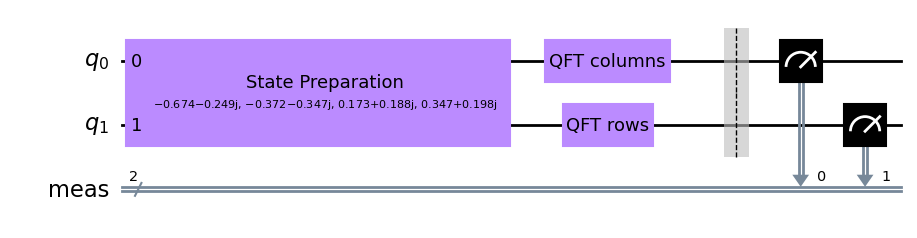

In [58]:
circuit = build_patch_circuit(patch)

# fold=-1 keeps it on one line: the state-preparation box is wide because it
# carries all four amplitudes, and wrapping splits it across rows.
display(circuit.draw(output="mpl", style="clifford", fold=-1))

Those boxes are composites rather than gates: `State Preparation` unpacks into
several operations. Counting the circuit as drawn gives five instructions, which
undercounts the work — the boxes hide their contents.

`decompose` opens one layer per call, and the composites nest, so reaching real
gates takes a few calls. How many is a property of the circuit, so the loop below
keeps opening until the result stops changing rather than assuming a number.

In [ ]:
"""
Changes from the original implementation:

- Replaced the count_ops() comparison with direct circuit equality (opened == levels[-1][1]) to check whether successive decomposition depths produce the same circuit, rather than merely containing the same number of each gate.

- Changed the return value to include a stabilized Boolean, indicating whether decomposition stopped because the circuit stopped changing.

- Added an explicit warning when the decomposition limit is reached without stabilization, instead of always claiming the circuit was fully decomposed.

- Renamed entangling to two_qubit_gates because not all two-qubit gates create entanglement (for example, SWAP gates).

- Clarified that the reported decomposition depth is the last distinct level recorded, not necessarily proof that every gate has been reduced to hardware-native operations.
"""

def decomposition_levels(circuit, limit=12):
    """Record successive decomposition depths until the circuit stabilizes.

    Returns:
        levels: List of (reps, circuit) pairs.
        stabilized: Whether two successive depths produced the same circuit.
    """
    # This stores each version of the circuit as it gets decomposed
    # Levels[(1, "decomposed once")], etc for 2, 3 , 4
    levels = [(0, circuit)]

    for reps in range(1, limit + 1):
        # The result of decomposing the original circuit to a particular depth.
        opened = circuit.decompose(reps=reps)

        if opened == levels[-1][1]:
            return levels, True

        levels.append((reps, opened))

    return levels, False


levels, stabilized = decomposition_levels(circuit)

for reps, opened in levels:
    two_qubit_gates = {
        instruction.operation.name
        for instruction in opened.data
        if isinstance(instruction.operation, Gate)
        and instruction.operation.num_qubits == 2
    }

    print(
        f"reps={reps}  {opened.size():>3} gates   "
        f"{', '.join(sorted(opened.count_ops())):<44} "
        f"2-qubit gates: "
        f"{', '.join(sorted(two_qubit_gates)) or 'none'}"
    )

DECOMPOSE_REPS = levels[-1][0]
print()

if stabilized:
    print(f"Circuit stabilized at decomposition depth {DECOMPOSE_REPS}.")
else:
    print(f"Circuit did not stabilize within {len(levels) - 1} passes.")


reps=0    5 gates   barrier, measure, qft, state_preparation     2-qubit gates: state_preparation
reps=1    5 gates   barrier, h, isometry_to_uncompute_dg, measure 2-qubit gates: isometry_to_uncompute_dg
reps=2    6 gates   barrier, measure, multiplexer_dg, u          2-qubit gates: multiplexer_dg
reps=3    8 gates   barrier, cx, measure, u, unitary             2-qubit gates: cx
reps=4    8 gates   barrier, cx, measure, u                      2-qubit gates: cx

Circuit stabilized at decomposition depth 4.


In [60]:
flat_circuit = circuit.decompose(reps=DECOMPOSE_REPS)

print(f"{'':<14} {'gates':>7} {'depth':>7}")
print(f"{'as written':<14} {circuit.size():>7} {circuit.depth():>7}")
print(f"{'decomposed':<14} {flat_circuit.size():>7} {flat_circuit.depth():>7}")

                 gates   depth
as written           5       3
decomposed           8       5


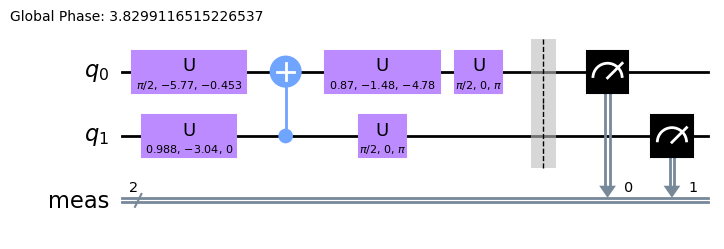

global phase: 3.8299
        ┌─────────────────────────┐┌───┐┌────────────────────────────┐»
   q_0: ┤ U(π/2,-5.7662,-0.45339) ├┤ X ├┤ U(0.87035,-1.4761,-4.7782) ├»
        └─┬──────────────────────┬┘└─┬─┘└───────┬────────────┬───────┘»
   q_1: ──┤ U(0.98766,-3.0399,0) ├───■──────────┤ U(π/2,0,π) ├────────»
          └──────────────────────┘              └────────────┘        »
meas: 2/══════════════════════════════════════════════════════════════»
                                                                      »
«        ┌────────────┐ ░ ┌─┐   
«   q_0: ┤ U(π/2,0,π) ├─░─┤M├───
«        └────────────┘ ░ └╥┘┌─┐
«   q_1: ───────────────░──╫─┤M├
«                       ░  ║ └╥┘
«meas: 2/══════════════════╩══╩═
«                          0  1 


"\nGeneral single-qubit unitary gate, UGate: U(θ, φ, λ)\nThe gate applies a rotation to a qubit's state, with the three angles specifying the operation\n\nThis is its matrix (for overleaf)\nU(\theta, \\phi, \\lambda) = \n\x08egin{pmatrix} \n\\cos\\left(\x0crac{\theta}{2}\right) & -e^{i\\lambda}\\sin\\left(\x0crac{\theta}{2}\right) \\ \ne^{i\\phi}\\sin\\left(\x0crac{\theta}{2}\right) & e^{i(\\phi + \\lambda)}\\cos\\left(\x0crac{\theta}{2}\right) \n\\end{pmatrix}\n\n\n"

In [61]:
display(flat_circuit.draw(output="mpl", style="clifford", fold=90))
print(flat_circuit)

"""
General single-qubit unitary gate, UGate: U(θ, φ, λ)
The gate applies a rotation to a qubit's state, with the three angles specifying the operation

This is its matrix (for overleaf)
U(\theta, \phi, \lambda) = 
\begin{pmatrix} 
\cos\left(\frac{\theta}{2}\right) & -e^{i\lambda}\sin\left(\frac{\theta}{2}\right) \\ 
e^{i\phi}\sin\left(\frac{\theta}{2}\right) & e^{i(\phi + \lambda)}\cos\left(\frac{\theta}{2}\right) 
\end{pmatrix}


"""

`u` and `cx` are still abstract: `u` is any single-qubit rotation, written as three
angles. No device has a gate called `u` — section 2 rewrites these into the ones a
device does have.

## 2. Optimize — rewriting it for the device

A device runs a fixed, small set of physical operations, and only between qubits
that are physically wired together. Transpilation rewrites the circuit into those
operations and places it on real qubits. IBM calls the result an ISA circuit, and
only these can be run
([Qiskit patterns](https://quantum.cloud.ibm.com/docs/en/guides/intro-to-patterns)).

In [62]:
def compile_for_device(circuit, backend, optimization_level=3):
    """Transpile a circuit for a target backend.

    Args:
        circuit: A Qiskit QuantumCircuit.
        backend: A supported Qiskit backend.
        optimization_level: Preset optimization level, from 0 to 3.

    Returns:
        A transpiled QuantumCircuit targeting the backend.
    """
    # Added a check
    if optimization_level not in range(4):
        raise ValueError("optimization_level must be between 0 and 3.")

    pass_manager = generate_preset_pass_manager(
        optimization_level=optimization_level,
        backend=backend,
    )
    return pass_manager.run(circuit)


def two_qubit_count(circuit):
    """Count two-qubit Gate instructions in a circuit.

    Measurements and barriers are excluded because they are not Gate
    instances. Other non-Gate operations are also excluded.

    Args:
        circuit: A Qiskit QuantumCircuit.

    Returns:
        Number of two-qubit Gate instructions.
    """
    return sum(
        1
        for instruction in circuit.data
        if isinstance(instruction.operation, Gate)
        and instruction.operation.num_qubits == 2
    )

In [63]:
# Set to True to transpile for the target backend.
# This does not mean the hardware must be online.
COMPILE_FOR_BACKEND = True

if COMPILE_FOR_BACKEND:
    isa_circuit = compile_for_device(circuit, backend)

    print(f"{'':<26} {'instructions':>12} {'2-qubit':>9}")
    print(f"{'what the algorithm asks':<26} "
          f"{flat_circuit.size():>12} "
          f"{two_qubit_count(flat_circuit):>9}")
    print(f"{'what ' + backend.name + ' runs':<26} "
          f"{isa_circuit.size():>12} "
          f"{two_qubit_count(isa_circuit):>9}")
    print()

    print(f"operations asked for: {dict(flat_circuit.count_ops())}")
    print(f"operations run: {dict(isa_circuit.count_ops())}")

    placed = sorted({
        isa_circuit.find_bit(qubit).index
        for instruction in isa_circuit.data
        for qubit in instruction.qubits
        if isinstance(instruction.operation, Gate)
        and instruction.operation.num_qubits == 2
    })

    print()
    print(f"Qubit indices used by 2-qubit gates: {placed}")
    print(f"Backend capacity: {backend.num_qubits} qubits")

else:
    isa_circuit = None
    print("Backend-targeted transpilation skipped.")

                           instructions   2-qubit
what the algorithm asks               8         1
what ibm_marrakesh runs              19         1

operations asked for: {'u': 5, 'measure': 2, 'cx': 1, 'barrier': 1}
operations run: {'rz': 9, 'sx': 7, 'measure': 2, 'cz': 1, 'barrier': 1}

Qubit indices used by 2-qubit gates: [53, 54]
Backend capacity: 156 qubits


The names change and the count grows: `u` becomes runs of `Rz` and `√X`, and `cx`
becomes a `cz` with rotations around it, because those are what the chip physically
performs.

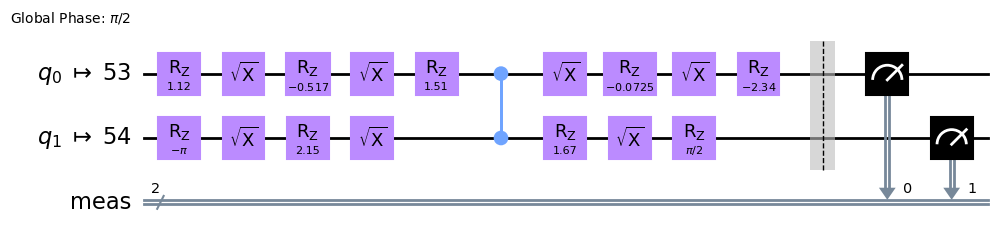

In [64]:
# idle_wires=False drops the 154 qubits this circuit never touches.
display(isa_circuit.draw(output="mpl", style="clifford",
                            idle_wires=False, fold=90))

## 3. Execute — running it

One run gives one outcome. The measurement leaves the state in whichever basis
state it returned, so the other amplitudes are unrecoverable and the state must be
prepared again for the next sample [6]. An amplitude is estimated from how often
its outcome came up, over 4096 runs here.

`SUBMIT` is left False, so this reproduces from the stored run in `results/` rather
than spending device time. Each job is written once, when it returned, with the
calibration in force at the time — the same circuit scores differently week to week,
so the counts are only interpretable next to it.

In [67]:
SUBMIT = True
USE_SIMULATOR = True
SHOTS = [4096, 8192, 16384, 32,768]
PATCH_SIDE = 2
RESULTS_DIR = Path("results/jobs")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [74]:
# Select target and compile the circuit
if USE_SIMULATOR:
    target = AerSimulator()
    target_name = "aer_simulator"
    execution_type = "simulator"
else:
    # Define `backend` before running this block.
    target = backend
    name = target.name
    target_name = name() if callable(name) else name
    execution_type = "hardware"

safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", target_name)

# Compile for the selected target.
isa_circuit = compile_for_device(circuit, target)

# Run each shot budget and collect counts
saved_budgets = {}
job_ids = []

if USE_SIMULATOR:
    for shots in SHOTS:
        job = target.run(isa_circuit, shots=shots)
        result = job.result()
        raw_counts = result.get_counts(isa_circuit)

        saved_budgets[str(shots)] = {
            "counts": {
                str(int(bits.replace(" ", ""), 2)): count
                for bits, count in raw_counts.items()
            }
        }
else:

    # Needs a test. Came from old code I've written so should work but cost money to run. Make separate ibm account later to get free credits
    sampler = Sampler(mode=target)
    sampler.options.default_shots = max(SHOTS)
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.twirling.enable_gates = True

    for shots in SHOTS:
        job = sampler.run([isa_circuit], shots=shots)
        job_ids.append(job.job_id())
        print(f"Submitted {shots} shots to {target_name}: {job.job_id()}")

        pub_result = job.result()[0]
        raw_counts = pub_result.data.meas.get_counts()

        saved_budgets[str(shots)] = {
            "counts": {
                str(int(bits.replace(" ", ""), 2)): count
                for bits, count in raw_counts.items()
            }
        }

# Save to a target-specific JSON file
record = {
    "backend": target_name,
    "execution_type": execution_type,
    "patch_side": PATCH_SIDE,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "shots_requested": SHOTS,
    "job_ids": job_ids,
    "budgets": saved_budgets,
}

output_path = RESULTS_DIR / (
    f"{safe_name}_{PATCH_SIDE}x{PATCH_SIDE}_shot_budgets.json"
)

with open(output_path, "w", encoding="utf-8") as handle:
    json.dump(record, handle, indent=2)

print(f"\nExecution type: {execution_type}")
print(f"Target: {target_name}")
print(f"Saved results: {output_path}")

# Load the newly saved JSON and process all results identically
with open(output_path, encoding="utf-8") as handle:
    stored = json.load(handle)

basis = "".join(
    f"{'|' + format(i, '02b') + '>':>8}" for i in range(4)
)

print(f"\n{'shots':>6} |{basis} |{basis}")
print(f"{'':>6} |{'counts':^32} |{'amplitude':^32}")
print("-" * 76)

for budget in sorted(stored["budgets"], key=int):
    counted = stored["budgets"][budget]["counts"]

    tally = np.array(
        [counted.get(str(i), 0) for i in range(4)],
        dtype=float,
    )

    total = tally.sum()
    estimate = np.sqrt(tally / total) if total else np.zeros(4)

    print(
        f"{int(budget):>6} |"
        + "".join(f"{value:>8,.0f}" for value in tally)
        + " |"
        + "".join(f"{value:>8.3f}" for value in estimate)
    )



Execution type: simulator
Target: aer_simulator
Saved results: results\jobs\aer_simulator_2x2_shot_budgets.json

 shots |    |00>    |01>    |10>    |11> |    |00>    |01>    |10>    |11>
       |             counts              |           amplitude            
----------------------------------------------------------------------------
    32 |       3       2      27       0 |   0.306   0.250   0.919   0.000
   768 |      60      37     659      12 |   0.280   0.219   0.926   0.125
  4096 |     345     250   3,480      21 |   0.290   0.247   0.922   0.072
  8192 |     649     460   7,016      67 |   0.281   0.237   0.925   0.090
 16384 |   1,311     924  14,037     112 |   0.283   0.237   0.926   0.083


### Estimating amplitudes from a finite sample

The same circuit ran at five shot budgets, as five separate jobs. Columns are the
four basis states measured, `|q1 q0>`, each naming one k-space position exactly as
in section 1.

## 4. Analyse — scoring it against the classical reconstruction

In [77]:
"""
Changes made:
- Added input validation to ensure `side` is a positive integer and
  `patch` is a square 2D array.

- Added validation for measurement counts, including invalid basis-state
  indices, negative counts, and zero total measurements.

- Added checks for zero-norm images and reference vectors to prevent
  division by zero during normalization and error calculation.

- Added shape and finite-value checks in `relative_l2` to ensure the
  recovered and reference vectors can be compared safely.

- Preserved the original mathematical operations: probability estimation
  from counts, square-root amplitude magnitudes, FFT shifting, classical
  inverse FFT reconstruction, normalization, and relative L2 error.
  
- Clarified that measurement counts recover amplitude magnitudes but not
  complex phases, so the comparison evaluates magnitude reconstructions
  rather than complete complex-valued MRI images.

"""
def magnitudes_from_counts(counts, side):
    """Estimate centered Fourier-domain amplitude magnitudes from counts.

    Assumes integer basis-state indices in the range [0, side**2 - 1].
    Measurement counts recover amplitude magnitudes, not phases.
    """
    if not isinstance(side, (int, np.integer)) or side <= 0:
        raise ValueError("side must be a positive integer.")

    tally = np.zeros(side * side, dtype=float)

    for index, number in counts.items():
        index = int(index)
        if not 0 <= index < side * side:
            raise ValueError(f"Invalid basis-state index: {index}")
        if number < 0:
            raise ValueError("Measurement counts cannot be negative.")
        tally[index] += number

    total = tally.sum()
    if total == 0:
        raise ValueError("Counts must contain at least one measurement.")

    estimate = np.sqrt(tally / total).reshape(side, side)
    return np.fft.fftshift(estimate).ravel()


def exact_magnitudes(patch):
    """Compute the normalized classical magnitude-image reference.

    Assumes a 2D complex k-space array with zero frequency centered.
    """
    patch = np.asarray(patch)
    if patch.ndim != 2 or patch.shape[0] != patch.shape[1]:
        raise ValueError("patch must be a square 2D array.")

    image = np.fft.ifft2(
        np.fft.ifftshift(patch), norm="ortho"
    )
    magnitudes = np.abs(np.fft.fftshift(image)).ravel()

    norm = np.linalg.norm(magnitudes)
    if norm == 0:
        raise ValueError("Cannot normalize an all-zero image.")

    return magnitudes / norm


def relative_l2(recovered, exact):
    """Compute relative L2 error between two magnitude vectors."""
    recovered = np.asarray(recovered)
    exact = np.asarray(exact)

    if recovered.shape != exact.shape:
        raise ValueError("Vectors must have matching shapes.")

    if not np.all(np.isfinite(recovered)) or not np.all(np.isfinite(exact)):
        raise ValueError("Vectors must contain only finite values.")

    denominator = np.linalg.norm(exact)
    if denominator == 0:
        raise ValueError("Reference vector must have nonzero norm.")

    return np.linalg.norm(recovered - exact) / denominator


In [79]:
recovered = magnitudes_from_counts(counts, 2)
exact = exact_magnitudes(patch)
error = relative_l2(recovered, exact)

shots = sum(counts.values())
# Rows follow the image after fftshift, so each is a pixel of the picture rather
# than a measured index; the basis column says which outcome fed it.
shifted = np.fft.fftshift(np.arange(4).reshape(2, 2)).ravel()

print(f"{'pixel':>7} {'basis':>7} {'count':>7} {'share':>8} {'device':>9} "
      f"{'classical':>10} {'diff':>8}")
for position, index in enumerate(shifted):
    pixel = f"[{position // 2},{position % 2}]"
    print(f"{pixel:>7} {'|' + format(index, '02b') + '>':>7} "
          f"{counts[index]:>7,} {counts[index] / shots:>8.4f} "
          f"{recovered[position]:>9.4f} {exact[position]:>10.4f} "
          f"{recovered[position] - exact[position]:>+8.4f}")
print()
print(f"relative error {error:.1%}, agreement {np.dot(recovered, exact):.4f}")

  pixel   basis   count    share    device  classical     diff
  [0,0]    |11>      31   0.0076    0.0870     0.0842  +0.0027
  [0,1]    |10>   3,523   0.8601    0.9274     0.9240  +0.0034
  [1,0]    |01>     246   0.0601    0.2451     0.2424  +0.0027
  [1,1]    |00>     296   0.0723    0.2688     0.2834  -0.0145

relative error 1.5%, agreement 0.9999


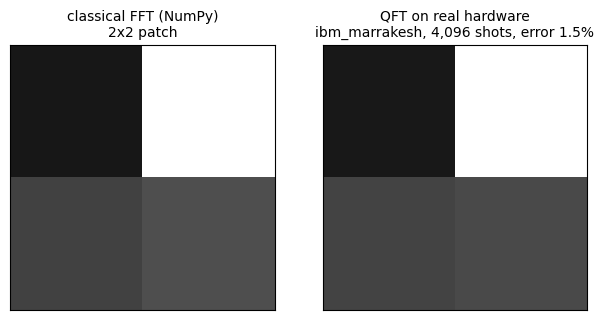

In [81]:
figure, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
scale = {"vmin": 0, "vmax": max(exact.max(), recovered.max())}

axes[0].imshow(exact.reshape(2, 2), cmap="gray", **scale)
axes[0].set_title(f"classical FFT (NumPy)\n2x2 patch", fontsize=10)

axes[1].imshow(recovered.reshape(2, 2), cmap="gray", **scale)
axes[1].set_title(f"QFT on real hardware\n{backend_name}, {shots:,} shots, "
                  f"error {error:.1%}", fontsize=10)

for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
figure.tight_layout()
plt.show()

## What this shows

Four k-space values were amplitude-encoded into two qubits, transformed by a QFT on
`ibm_kingston`, and recovered from 4096 measurements. Both quantities reported
above compare the recovered vector $r$ against the classical reconstruction $e$,
each normalised to unit length:

$$\text{relative error} = \frac{\lVert r - e \rVert}{\lVert e \rVert},
\qquad \text{agreement} = r \cdot e$$

The error is the length of the difference between the two images as a fraction of
the reference's own length.

### What it costs in time

Both routes take the same four values and return four transformed ones, so that is
what to time on each side.

In [89]:
WIDTH = 36


def header(title, unit):
    """A table heading and its rule."""
    print(f"{title:<{WIDTH}}{unit:>13}")
    print("-" * (WIDTH + 13))


def row(label, value, places=3):
    """One labelled number, aligned under the heading."""
    print(f"{label:<{WIDTH}}{value:>13.{places}f}")


def device_duration(circuit):
    """Seconds this circuit occupies the device, from its scheduled gates.

    Scheduling assigns each gate its calibrated pulse length, so this is physical
    time on the chip rather than wall-clock time in Python.

    Args:
        circuit: An abstract circuit to schedule for the pinned backend.

    Returns:
        Float seconds.
    """
    scheduled = transpile(circuit, backend=backend, scheduling_method="asap",
                          optimization_level=3)
    ends = [scheduled.qubit_stop_time(qubit) for qubit in scheduled.qubits]
    return max(ends) * backend.configuration().dt


def without_measurements(circuit):
    """The same circuit with its final measurements removed."""
    return circuit.remove_final_measurements(inplace=False)


gates = shot = None
gates = device_duration(without_measurements(circuit))
shot = device_duration(circuit)
print(type(shot), repr(shot))
print(type(SHOTS), repr(SHOTS))

header("on the device", "microseconds")
row("encoding and the QFT", gates * 1e6)
row("readout", (shot - gates) * 1e6)
row("one shot, start to finish", shot * 1e6)
for n in SHOTS:
    row(f"all {n} shots", shot * n * 1e6)

<class 'float'> 2.8960000000000003e-06
<class 'list'> [4096, 8192, 16384, 32, 768]
on the device                        microseconds
-------------------------------------------------
encoding and the QFT                        0.212
readout                                     2.684
one shot, start to finish                   2.896
all 4096 shots                          11862.016
all 8192 shots                          23724.032
all 16384 shots                         47448.064
all 32 shots                               92.672
all 768 shots                            2224.128


In [91]:
def fastest(function, batch=20_000, repeats=5):
    """Seconds per call, best batch of several.

    The best batch rather than the median: for something this short, a median
    still absorbs whatever else the machine is doing.

    Args:
        function: Callable taking no arguments.
        batch: Calls per batch.
        repeats: Batches to run.

    Returns:
        Float seconds per call.
    """
    return min(timeit.repeat(function, number=batch, repeat=repeats)) / batch


def inverse_fft_1d(values):
    """Inverse DFT of a power-of-two sequence, by Cooley-Tukey recursion.

    Splits into even- and odd-indexed halves, transforms each, and combines
    them. Unscaled: the caller applies the normalisation once.

    Args:
        values: Sequence of complex values, length a power of two.

    Returns:
        List of complex values, same length.
    """
    length = len(values)
    if length == 1:
        return list(values)

    even = inverse_fft_1d(values[0::2])
    odd = inverse_fft_1d(values[1::2])

    output = [0j] * length
    for index in range(length // 2):
        # exp(+...) for the inverse transform; the forward one negates it.
        twiddle = cmath.exp(2j * cmath.pi * index / length) * odd[index]
        output[index] = even[index] + twiddle
        output[index + length // 2] = even[index] - twiddle
    return output


def inverse_fft_2d(values, side):
    """Inverse 2D FFT: the 1D transform along the rows, then the columns.

    Args:
        values: The side*side complex inputs, row-major.
        side: Length of each axis, a power of two.

    Returns:
        List of side*side complex values, matching
        np.fft.ifft2(..., norm="ortho").
    """
    rows = [inverse_fft_1d(values[start:start + side])
            for start in range(0, side * side, side)]
    columns = [inverse_fft_1d([row[index] for row in rows])
               for index in range(side)]

    scale = 1 / side  # ortho: 1/sqrt(side ** 2)
    return [columns[column][row] * scale
            for row in range(side) for column in range(side)]


values = list(patch.ravel())
assert np.allclose(inverse_fft_2d(values, 2),
                   np.fft.ifft2(patch, norm="ortho").ravel())

header("four values in, four values out", "microseconds")
row("Cooley-Tukey, written out",
    fastest(lambda: inverse_fft_2d(values, 2), batch=50_000) * 1e6)
row("the same through np.fft.ifft2",
    fastest(lambda: np.fft.ifft2(patch, norm="ortho")) * 1e6)
if shot is not None:
    for n in SHOTS:
        row(f"all {n} shots", shot * n * 1e6)

four values in, four values out      microseconds
-------------------------------------------------
Cooley-Tukey, written out                   9.356
the same through np.fft.ifft2              23.429
all 4096 shots                          11862.016
all 8192 shots                          23724.032
all 16384 shots                         47448.064
all 32 shots                               92.672
all 768 shots                            2224.128


## References

1. M. Lyu, L. Mei, S. Huang, et al. "M4Raw: A multi-contrast, multi-repetition,
   multi-channel MRI k-space dataset for low-field MRI research."
   *Scientific Data* **10**, 264, 2023.
   [doi:10.1038/s41597-023-02181-4](https://doi.org/10.1038/s41597-023-02181-4)
2. IBM Quantum. "Introduction to Qiskit patterns."
   [quantum.cloud.ibm.com/docs/en/guides/intro-to-patterns](https://quantum.cloud.ibm.com/docs/en/guides/intro-to-patterns)
3. M. A. Nielsen and I. L. Chuang. *Quantum Computation and Quantum Information*,
   10th anniversary ed. Cambridge University Press, 2010. §2.2.3, Postulate 3: a
   measurement returns outcome $m$ with probability
   $p(m) = \langle\psi|M_m^\dagger M_m|\psi\rangle$, which for a computational-basis
   measurement is $|a_m|^2$ — the rule the whole readout rests on. §5.1: the QFT
   circuit, and why its amplitudes cannot be read out directly.
4. R. Mezrich. "A perspective on k-space." *Radiology* **195**(2), 297–315, 1995.
   [doi:10.1148/radiology.195.2.7724743](https://doi.org/10.1148/radiology.195.2.7724743)
   Review article. The aperture experiment of its Figures 5 and 6, and its
   caution that centre and periphery shade into one another rather than
   dividing sharply.
5. IBM Quantum. *Quantum Machine Learning*, "Data encoding."
   [quantum.cloud.ibm.com/learning/courses/quantum-machine-learning/data-encoding](https://quantum.cloud.ibm.com/learning/courses/quantum-machine-learning/data-encoding)
   Source of the amplitude-encoding definition and the normalisation requirement.
   `brain_kspace_qft.ipynb` section 3 compares all five schemes it defines.
6. T. Brunet, E. Tolley, S. Corda, et al. "Quantum Radio Astronomy: Data Encodings
   and Quantum Image Processing." *Astronomy and Computing*,
   [arXiv:2310.12084](https://arxiv.org/abs/2310.12084), 2024. Section 2 states the
   repeat-and-measure mechanism; the paper benchmarks QPIE, the encoding used
   here, against FRQI and quantum lattice.
7. B. T. Kiani, A. Villanyi and S. Lloyd. "Quantum Medical Imaging Algorithms."
   [arXiv:2004.02036](https://arxiv.org/abs/2004.02036), 2020. MRI reconstruction
   as an inverse 2D QFT in $O(\log^2 N)$, stated for data "input as a quantum
   state"; its section 5 gives the $O(N^2)$ readout cost that cancels the speedup
   unless the state is post-processed rather than measured.
8. J. W. Cooley and J. W. Tukey. "An algorithm for the machine calculation of
   complex Fourier series." *Mathematics of Computation* **19**, 297-301, 1965.
   [doi:10.1090/S0025-5718-1965-0178586-1](https://doi.org/10.1090/S0025-5718-1965-0178586-1)
   The algorithm `np.fft` implements, which its module documentation cites.